<a href="https://colab.research.google.com/github/gleisspe/Libraries-Python---Data-Science-Studies-/blob/main/Supply_Chain_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
import pandas as pd
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [55]:
import os

# Baixa os arquivos do dataset do Kaggle
path = kagglehub.dataset_download("harshsingh2209/supply-chain-analysis")

# Lê o arquivo CSV principal do dataset
# (ajuste o nome do arquivo se necessário com base na lista impressa acima)
csv_path = os.path.join(path, "supply_chain_data.csv")
df = pd.read_csv(csv_path)

# Exibe as primeiras linhas do DataFrame
df.head()

Using Colab cache for faster access to the 'supply-chain-analysis' dataset.


,Product type,SKU,Price,Availability,Number of products sold,Revenue generated,Customer demographics,Stock levels,Lead times,Order quantities,...,Location,Lead time,Production volumes,Manufacturing lead time,Manufacturing costs,Inspection results,Defect rates,Transportation modes,Routes,Costs
0,haircare,SKU0,69.808006,55,802,8661.996792,Non-binary,58,7,96,...,Mumbai,29,215,29,46.279879,Pending,0.226410,Road,Route B,187.752075
1,skincare,SKU1,14.843523,95,736,7460.900065,Female,53,30,37,...,Mumbai,23,517,30,33.616769,Pending,4.854068,Road,Route B,503.065579
2,haircare,SKU2,11.319683,34,8,9577.749626,Unknown,1,10,88,...,Mumbai,12,971,27,30.688019,Pending,4.580593,Air,Route C,141.920282
3,skincare,SKU3,61.163343,68,83,7766.836426,Non-binary,23,13,59,...,Kolkata,24,937,18,35.624741,Fail,4.746649,Rail,Route A,254.776159
4,skincare,SKU4,4.805496,26,871,2686.505152,Non-binary,5,3,56,...,Delhi,5,414,3,92.065161,Fail,3.145580,Air,Route A,923.440632


In [56]:
# Exibe os tipos de dados de cada coluna no DataFrame e na sequencia exibir o tamanho do dataset
df.dtypes
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Product type             100 non-null    object 
 1   SKU                      100 non-null    object 
 2   Price                    100 non-null    float64
 3   Availability             100 non-null    int64  
 4   Number of products sold  100 non-null    int64  
 5   Revenue generated        100 non-null    float64
 6   Customer demographics    100 non-null    object 
 7   Stock levels             100 non-null    int64  
 8   Lead times               100 non-null    int64  
 9   Order quantities         100 non-null    int64  
 10  Shipping times           100 non-null    int64  
 11  Shipping carriers        100 non-null    object 
 12  Shipping costs           100 non-null    float64
 13  Supplier name            100 non-null    object 
 14  Location                 10

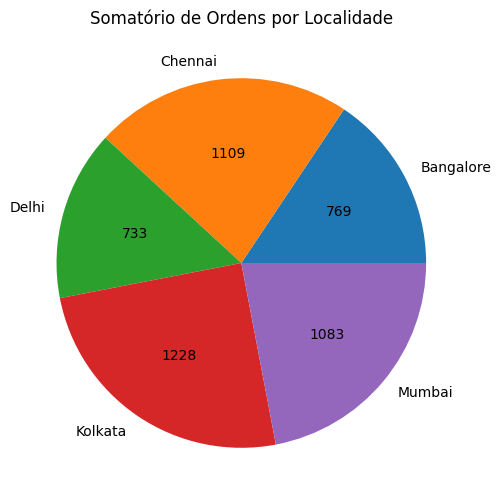

In [57]:
plt.figure(figsize=(10, 6))
# Agrupa os dados gerando uma Serie unidimensional (1D)
dados_agrupados = df.groupby('Location')['Order quantities'].sum()

# Função para converter a porcentagem de volta para o valor absoluto correspondente
def func_valor_absoluto(pct):
    total = sum(dados_agrupados)
    val = int(round(pct * total / 100.0))
    return f'{val}'

plt.pie(dados_agrupados, labels=dados_agrupados.index, autopct=func_valor_absoluto)
plt.title('Somatório de Ordens por Localidade')
plt.show()

In [58]:
#Criação do array para calcular a correlação
Features = ['Price', 'Availability', 'Number of products sold', 'Revenue generated', 'Lead times', 'Lead time', 'Manufacturing costs','Stock levels']
x = df[Features].dropna().values
x

array([[6.98080055e+01, 5.50000000e+01, 8.02000000e+02, 8.66199679e+03,
        7.00000000e+00, 2.90000000e+01, 4.62798792e+01, 5.80000000e+01],
       [1.48435233e+01, 9.50000000e+01, 7.36000000e+02, 7.46090007e+03,
        3.00000000e+01, 2.30000000e+01, 3.36167690e+01, 5.30000000e+01],
       [1.13196833e+01, 3.40000000e+01, 8.00000000e+00, 9.57774963e+03,
        1.00000000e+01, 1.20000000e+01, 3.06880193e+01, 1.00000000e+00],
       [6.11633430e+01, 6.80000000e+01, 8.30000000e+01, 7.76683643e+03,
        1.30000000e+01, 2.40000000e+01, 3.56247414e+01, 2.30000000e+01],
       [4.80549604e+00, 2.60000000e+01, 8.71000000e+02, 2.68650515e+03,
        3.00000000e+00, 5.00000000e+00, 9.20651606e+01, 5.00000000e+00],
       [1.69997601e+00, 8.70000000e+01, 1.47000000e+02, 2.82834875e+03,
        2.70000000e+01, 1.00000000e+01, 5.67664756e+01, 9.00000000e+01],
       [4.07833286e+00, 4.80000000e+01, 6.50000000e+01, 7.82347656e+03,
        1.50000000e+01, 1.40000000e+01, 1.08506857e+00, 1.

In [59]:
#Cálculo da correlação
correlação = np.corrcoef(x.T)
correlação

array([[ 1.        ,  0.01908273,  0.00573948,  0.0384244 ,  0.04485467,
         0.152185  , -0.18412306,  0.07826098],
       [ 0.01908273,  1.        ,  0.08749624, -0.07517047,  0.17043898,
        -0.15666861,  0.13465229, -0.02589985],
       [ 0.00573948,  0.08749624,  1.        , -0.00164125, -0.04641872,
         0.0412303 ,  0.03428415,  0.02218948],
       [ 0.0384244 , -0.07517047, -0.00164125,  1.        , -0.0572961 ,
        -0.01417768, -0.21402507, -0.15847968],
       [ 0.04485467,  0.17043898, -0.04641872, -0.0572961 ,  1.        ,
        -0.00281763, -0.0244405 ,  0.07257054],
       [ 0.152185  , -0.15666861,  0.0412303 , -0.01417768, -0.00281763,
         1.        , -0.12199915,  0.06787992],
       [-0.18412306,  0.13465229,  0.03428415, -0.21402507, -0.0244405 ,
        -0.12199915,  1.        ,  0.03324344],
       [ 0.07826098, -0.02589985,  0.02218948, -0.15847968,  0.07257054,
         0.06787992,  0.03324344,  1.        ]])

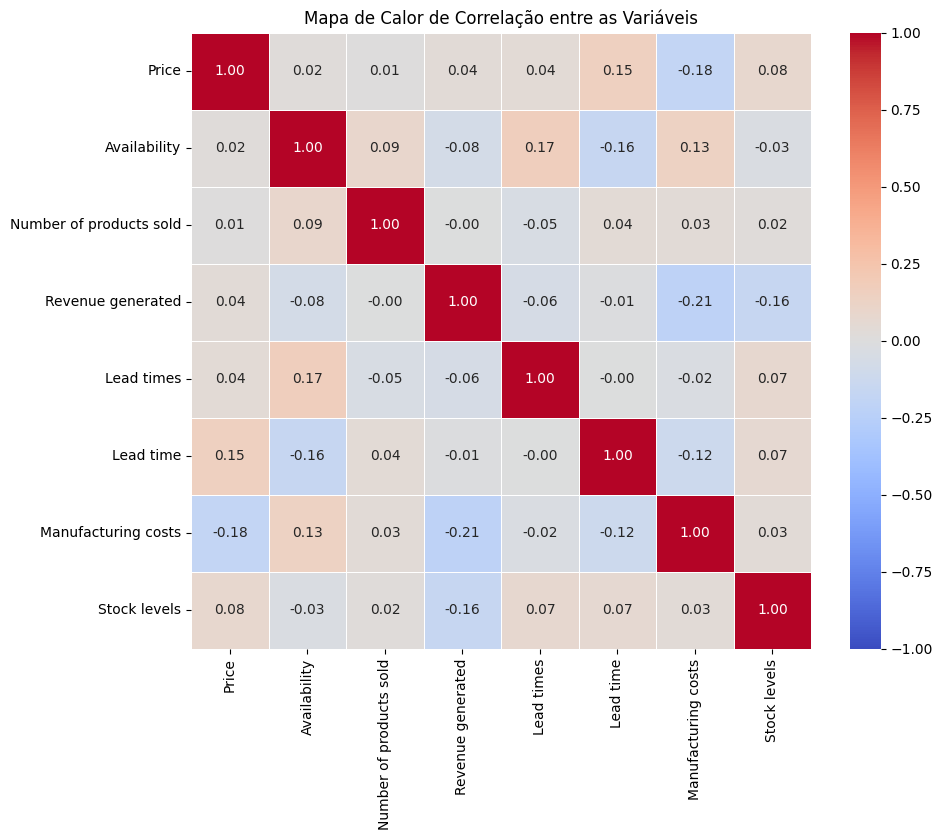

In [60]:
# Criamos um DataFrame do Pandas para a correlação, mapeando os nomes das Features
corr_df = df[Features].corr()

# Criando um mapa de calor visual para identificar facilmente as relações
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlação entre as Variáveis')
plt.show()

In [63]:
# 1) Criação de métricas financeiras e de eficiência
df_analise = df.copy()
df_analise['Profit'] = df_analise['Revenue generated'] - df_analise['Costs']

# 2) Agrupamento por Localização (Planta)
planta_stats = df_analise.groupby('Location').agg(
    Total_Profit=('Profit', 'sum'),
    Total_Revenue=('Revenue generated', 'sum'),
    Total_Products_Sold=('Number of products sold', 'sum'),
    Mean_Stock_Level=('Stock levels', 'mean'),
    Mean_Manufacturing_Cost=('Manufacturing costs', 'mean'),
    Total_Costs=('Costs', 'sum')
).reset_index()

# 3) Cálculo do Giro de Estoque Estimado (Vendas Totais / Estoque Médio)
planta_stats['Stock_Turnover_Index'] = planta_stats['Total_Products_Sold'] / planta_stats['Mean_Stock_Level']

# Ordenar pelo lucro total para o ranking
planta_stats = planta_stats.sort_values(by='Total_Profit', ascending=False)

print("--- RANKING GERAL DAS PLANTAS (Ordenado por Lucro Líquido) ---")
display(planta_stats.style.format({
    'Total_Profit': 'R$ {:.2f}',
    'Total_Revenue': 'R$ {:.2f}',
    'Total_Costs': 'R$ {:.2f}',
    'Total_Products_Sold': '{:,.0f}',
    'Mean_Stock_Level': '{:.1f}',
    'Mean_Manufacturing_Cost': 'R$ {:.2f}',
    'Stock_Turnover_Index': '{:.2f}'
}))

--- RANKING GERAL DAS PLANTAS (Ordenado por Lucro Líquido) ---


,Location,Total_Profit,Total_Revenue,Total_Products_Sold,Mean_Stock_Level,Mean_Manufacturing_Cost,Total_Costs,Stock_Turnover_Index
4,Mumbai,R$ 128331.50,R$ 137755.03,"9,426",42.4,R$ 36.73,R$ 9423.53,222.50
3,Kolkata,R$ 124795.81,R$ 137077.55,"12,770",57.6,R$ 41.86,R$ 12281.75,221.86
1,Chennai,R$ 106707.80,R$ 119142.82,"8,768",40.0,R$ 51.15,R$ 12435.01,219.47
0,Bangalore,R$ 92041.00,R$ 102601.72,"5,420",47.6,R$ 61.99,R$ 10560.72,113.97
2,Delhi,R$ 72804.13,R$ 81027.70,"9,715",50.1,R$ 48.88,R$ 8223.57,194.04


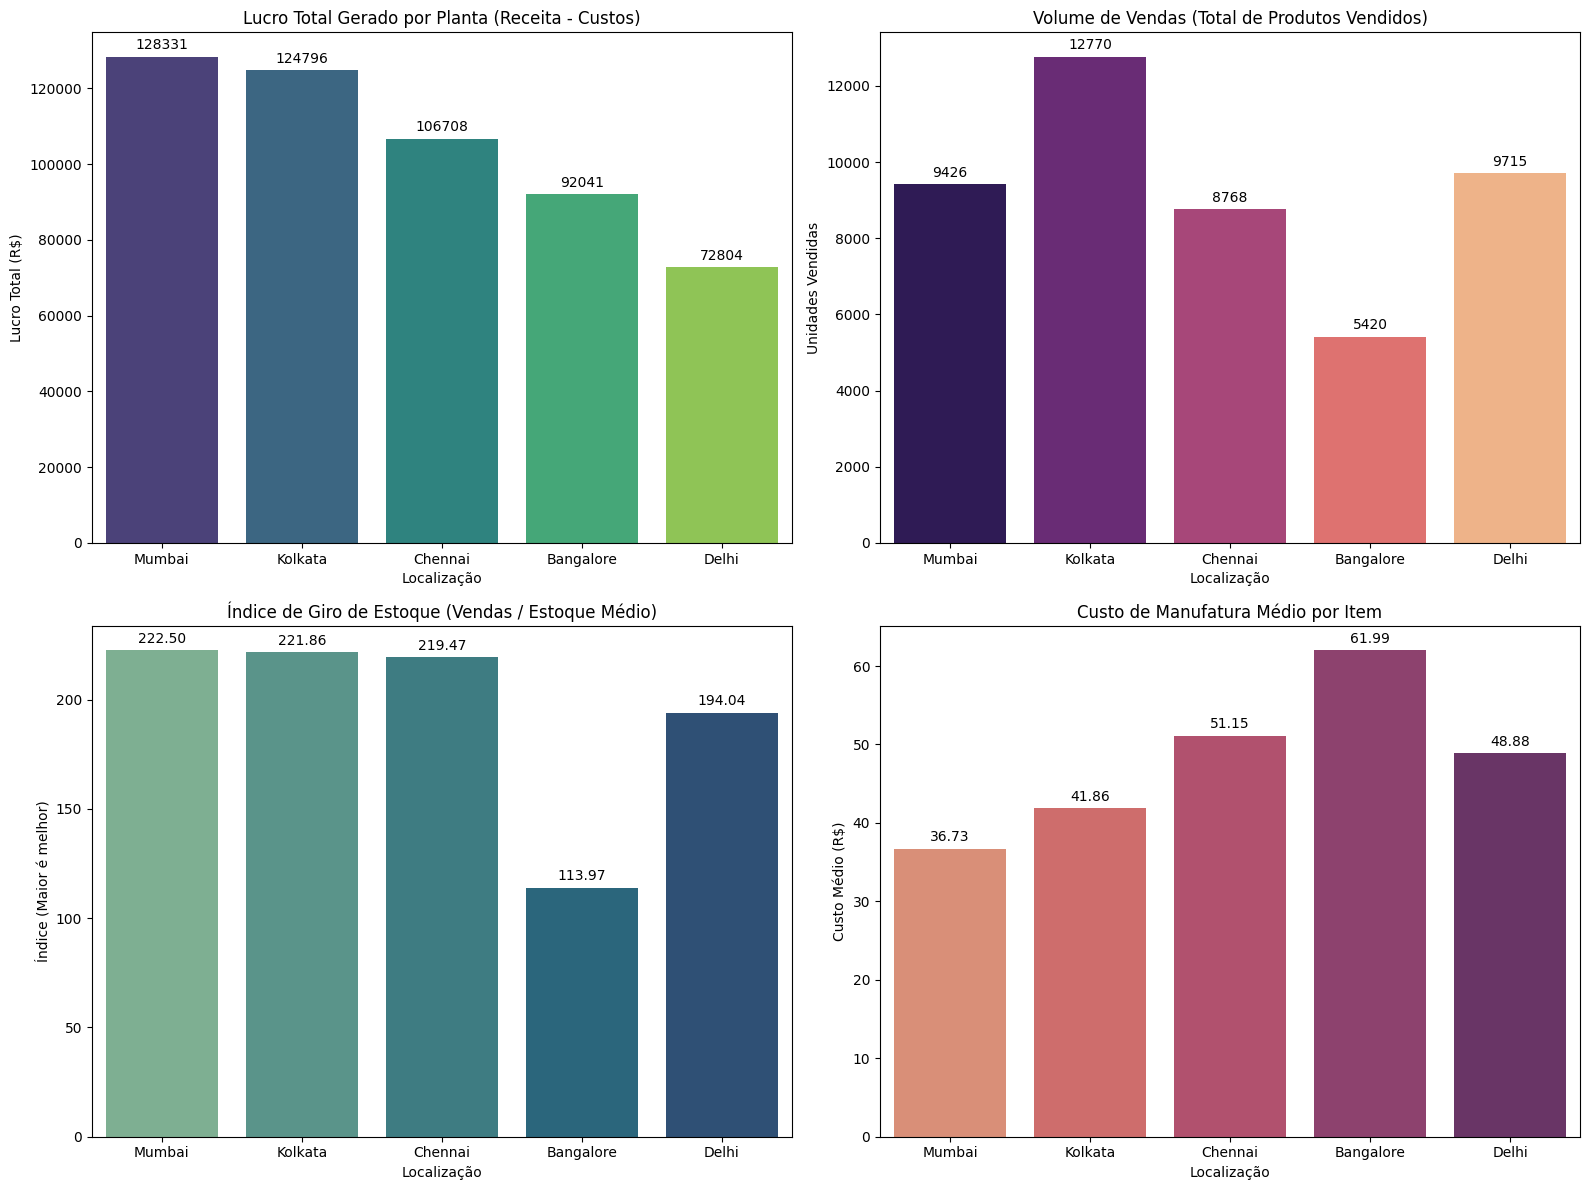

In [64]:
# 4) Visualização Gráfica dos KPIs para Tomada de Decisão
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Gráfico 1: Lucro Total por Planta
sns.barplot(ax=axes[0, 0], x='Location', y='Total_Profit', data=planta_stats, palette='viridis', hue='Location', legend=False)
axes[0, 0].set_title('Lucro Total Gerado por Planta (Receita - Custos)')
axes[0, 0].set_ylabel('Lucro Total (R$)')
axes[0, 0].set_xlabel('Localização')
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt='%.0f', padding=3)

# Gráfico 2: Produtos Vendidos
sns.barplot(ax=axes[0, 1], x='Location', y='Total_Products_Sold', data=planta_stats, palette='magma', hue='Location', legend=False)
axes[0, 1].set_title('Volume de Vendas (Total de Produtos Vendidos)')
axes[0, 1].set_ylabel('Unidades Vendidas')
axes[0, 1].set_xlabel('Localização')
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt='%.0f', padding=3)

# Gráfico 3: Índice de Giro de Estoque (Eficiência)
sns.barplot(ax=axes[1, 0], x='Location', y='Stock_Turnover_Index', data=planta_stats, palette='crest', hue='Location', legend=False)
axes[1, 0].set_title('Índice de Giro de Estoque (Vendas / Estoque Médio)')
axes[1, 0].set_ylabel('Índice (Maior é melhor)')
axes[1, 0].set_xlabel('Localização')
for container in axes[1, 0].containers:
    axes[1, 0].bar_label(container, fmt='%.2f', padding=3)

# Gráfico 4: Custos de Manufatura Médios
sns.barplot(ax=axes[1, 1], x='Location', y='Mean_Manufacturing_Cost', data=planta_stats, palette='flare', hue='Location', legend=False)
axes[1, 1].set_title('Custo de Manufatura Médio por Item')
axes[1, 1].set_ylabel('Custo Médio (R$)')
axes[1, 1].set_xlabel('Localização')
for container in axes[1, 1].containers:
    axes[1, 1].bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()